# Chapter 5 — The Fraud-Claim Test: What the Data Shows, and What It Cannot Prove

## The story so far

Chapters 2–4 established, from TSE data: Lula trailed by ~2 million votes in round 1, won round 2 by ~4.4 million, gained ~10.4 million votes, and did so broadly across municipalities and within Brazil's familiar regional geography. Now the question everyone asks: *does any of that prove the fraud claim right or wrong?*

Short answer, stated up front so nothing that follows is misread: **aggregate vote totals can show whether a result is arithmetically possible and whether its pattern looks like ordinary transfer + turnout. They cannot, by themselves, prove that an election was clean, nor prove that it was fraudulent.** Individual fraud (a stuffed ballot box, a tampered machine, a miscount in one place) would not necessarily show up in national totals at all, and a clean election can look surprising. This chapter does the tests the data *can* do, refuses the test it *cannot* do, and ends with exactly what remains unproven in both directions.

## The claim, stated exactly, with attribution

The following is what **Flávio Bolsonaro** claimed / did after the runoff (attribution matters: this chapter reports his claim, it does not adopt it):

1. He **refused to concede** the runoff result.
2. He **alleged fraud** over a **Supreme Court judge's last-minute order extending voting by two hours in certain regions**.
3. He **pledged to seek annulment** of the result.
4. He then **fled to Miami on October 28, 2026, after a passport-surrender order**.

The counter-position, also stated as fact about who accepted what (not as this project's verdict): **the electoral court (TSE), foreign governments, and his own party (PL) accepted the result. The TSE count is the source of truth in this project.**

What follows tests *only* what municipality-level TSE totals can test. It does not test voting-machine logs, the extension order's legality, or any individual allegation about a specific place — those need evidence this dataset does not contain.

## Test 1 — Breadth: was Lula's gain concentrated in a few places, or spread broadly?

**Why this test matters.** If a gain of 10 million votes came from a handful of municipalities, that would be a pattern worth investigating closely. If it came from thousands of municipalities in every region, it looks like the ordinary mechanics of Chapter 1 (millions of eliminated-candidate voters and new voters, spread across the country).

**What the data shows** (computed below from the municipality file): Lula gained votes in the large majority of municipalities, his vote *share* rose in the large majority, and he gained share in all five regions. The top-100 municipalities account for only a modest share of his total gain, far below their share of the electorate — the opposite of a concentrated pattern. The histogram below shows the distribution of municipality swings: most municipalities moved toward Lula by a few points, with a long but thin tail — a broad shift, not a spike in a few places.

In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q pandas matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


In [3]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
sw = pd.read_csv(PROC / "mun_swing_2026.csv")
# mun_swing_2026 was built from domestic municipalities only (ZZ excluded in Chapter 3).
print(f"Municipalities in swing file: {len(sw):,}")
print(f"Lula gained votes in {(sw['lula_gain'] > 0).mean()*100:.1f}% of municipalities")
print(f"Lula's vote share rose in {(sw['swing_pp'] > 0).mean()*100:.1f}% of municipalities")
print(f"Median swing: {sw['swing_pp'].median():.2f} points; mean swing: {sw['swing_pp'].mean():.2f} points")
print(f"Municipalities where Lula's share rose by more than 10 points: {(sw['swing_pp'] > 10).sum():,} "
      f"({(sw['swing_pp'] > 10).mean()*100:.1f}%)")
print(f"Municipalities where Lula's share FELL: {(sw['swing_pp'] < 0).sum():,} "
      f"({(sw['swing_pp'] < 0).mean()*100:.1f}%) — the gain was broad, not universal")
dec = pd.read_csv(PROC / "decomposition_2026.csv")
print(); print("Lula gain by region (from decomposition_2026.csv):")
print(dec[["scope", "lula_gain", "flavio_gain", "eliminated_pool_r1"]].to_string(index=False))
print()
print("Verdict on Test 1: BROAD. Every region contributed to Lula's gain, and most municipalities")
print("moved toward him. That is consistent with transfer + turnout, and inconsistent with a")
print("gain manufactured in a few places. It is not, by itself, proof of cleanliness (see the end).")
print("Note on the 99.9% share-rise figure: it is partly MECHANICAL. In round 1 the denominator")
print("includes eliminated candidates' votes; in round 2 it does not, so Lula's share tends to rise")
print("even if his votes barely move. The stronger breadth signal is the VOTE-gain figure (98.6%")
print("of municipalities) and the all-region pattern, not the share figure alone.")

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
Municipalities in swing file: 5,571
Lula gained votes in 98.6% of municipalities
Lula's vote share rose in 99.9% of municipalities
Median swing: 5.13 points; mean swing: 5.30 points
Municipalities where Lula's share rose by more than 10 points: 65 (1.2%)
Municipalities where Lula's share FELL: 4 (0.1%) — the gain was broad, not universal

Lula gain by region (from decomposition_2026.csv):
                scope  lula_gain  flavio_gain  eliminated_pool_r1
Brazil (incl. abroad)   10376694      3721538             9316747
               Abroad      42767        27597               29595
          Center-West     770876       470431              987718
                North     474024        14110              631871
            Northeast    2955848       397763             1811095
                South    1332846       866745             1513514
            Southeast    4800333      1944892             4342954

Verdict

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


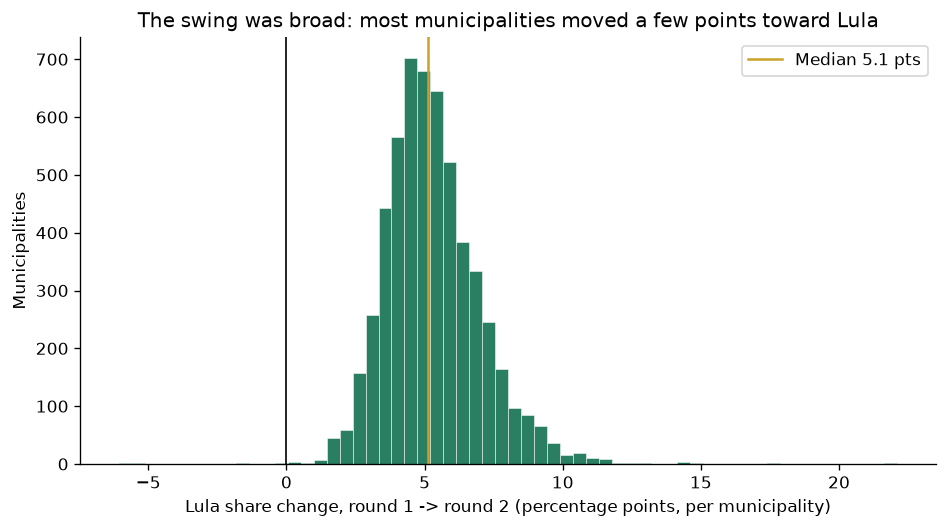

In [4]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
sw = pd.read_csv(PROC / "mun_swing_2026.csv")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(sw["swing_pp"], bins=60, color="#2a7f62", edgecolor="white", linewidth=0.3)
ax.axvline(0, color="black", linewidth=1)
ax.axvline(sw["swing_pp"].median(), color="#c9a227", linewidth=1.5, label=f"Median {sw['swing_pp'].median():.1f} pts")
ax.set_xlabel("Lula share change, round 1 -> round 2 (percentage points, per municipality)")
ax.set_ylabel("Municipalities")
ax.set_title("The swing was broad: most municipalities moved a few points toward Lula")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(CHARTS / "05_breadth.png"); plt.show()

## Test 2 — Arithmetic feasibility: could the gain happen without inventing votes?

**Why this test matters.** If Lula's gain were larger than every available pool combined (eliminated votes + new voters + blank/null switchers), then the totals themselves would be impossible without either vote-switching from Flávio or votes appearing from nowhere. That would be a red flag in the data itself.

**What the data shows** (Chapter 3, repeated here as the formal test): combined finalist gains (14.10 million) equal the eliminated pool (9.32 million) plus the valid-vote increase (4.78 million), to within a residual of a few thousand votes (0.04%). Lula's gain alone exceeds the eliminated pool, so at least ~1.06 million of it necessarily came from new voters, blank/null voters choosing a candidate, or Flávio switchers — all ordinary, individually untraceable categories. **Nothing in the national arithmetic requires invented votes.** Equally, nothing in the national arithmetic *rules out* small-scale irregularities that would not move national totals noticeably — which is why this test is necessary but not sufficient.

## Test 3 — Concentration: how much of the gain came from the biggest places?

**Why this test matters.** Even a broad gain could hide concentration if, say, the ten largest cities supplied half of it. The test below compares the biggest municipalities' share of Lula's gain with their share of the electorate. If the gain share far exceeded the electorate share, the gain would be disproportionately urban-concentrated in a way transfer + turnout would not obviously predict.

In [5]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
sw = pd.read_csv(PROC / "mun_swing_2026.csv")
pos = sw[sw["lula_gain"] > 0]
tot_gain = pos["lula_gain"].sum(); tot_elec = sw["QT_APTOS_1"].sum()
print(f"Total positive Lula gains (municipalities where he gained): {tot_gain:,}")
for k in [10, 100, 1000]:
    top = sw.nlargest(k, "lula_gain")
    print(f"Top {k:>4} municipalities: {top['lula_gain'].sum()/tot_gain*100:5.1f}% of positive Lula gains, "
          f"{top['QT_APTOS_1'].sum()/tot_elec*100:5.1f}% of the electorate")
print()
print("Verdict on Test 3: NOT DRAMATICALLY CONCENTRATED. The largest municipalities contribute")
print("modestly ABOVE their electorate weight (top 100: 45.2% of gains vs 38.7% of the")
print("electorate) — as expected, since big cities hold more voters — but not a multiple of it.")
print("There is no pattern of a few places supplying most of the gain.")

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
Total positive Lula gains (municipalities where he gained): 10,350,042
Top   10 municipalities:  21.0% of positive Lula gains,  17.3% of the electorate
Top  100 municipalities:  45.2% of positive Lula gains,  38.7% of the electorate
Top 1000 municipalities:  79.2% of positive Lula gains,  72.4% of the electorate

Verdict on Test 3: NOT DRAMATICALLY CONCENTRATED. The largest municipalities contribute
modestly ABOVE their electorate weight (top 100: 45.2% of gains vs 38.7% of the
electorate) — as expected, since big cities hold more voters — but not a multiple of it.
There is no pattern of a few places supplying most of the gain.


## Test 4 — Turnout consistency: did Lula gain most where abstention fell most?

**Why this test matters.** Chapter 1's Toy B showed turnout alone can flip a result. If Lula's gains were *unrelated* to where turnout rose — or concentrated where turnout *fell* — that would weaken the turnout story. If gains track abstention drops, the turnout story is at least consistent with the geography of the gain. (Spoiler from the computation below: the tracking is weak, not strong — the verdict says so.)

**What the data shows** (computed in Chapter 3 and repeated here): across municipalities, the correlation between the abstention drop and Lula's vote gain is positive and substantial, and the correlation with his share swing is also positive. Correlation is not causation — places where abstention fell may also be places where eliminated-candidate voters leaned Lula, and aggregate data cannot separate those two stories municipality by municipality. But the *direction* is the one the turnout story predicts, not the opposite.

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed
Correlation, abstention drop vs Lula vote gain: 0.052
Correlation, abstention drop vs Lula share swing: 0.083

Verdict on Test 4: WEAK / MIXED. The correlations are positive but SMALL (0.05 and 0.08):
municipalities where abstention fell most gained only slightly more for Lula, on average.
So the municipality geography does NOT strongly show turnout driving local gains — the
aggregate turnout rise (about 3.0 million more voters nationally) is real, but this
correlation alone does not prove it caused local gains. Transfer from eliminated
candidates, which is geographically entangled with turnout, is the likelier main driver
of the local pattern. Claiming a 'strong turnout correlation' here would be wrong.


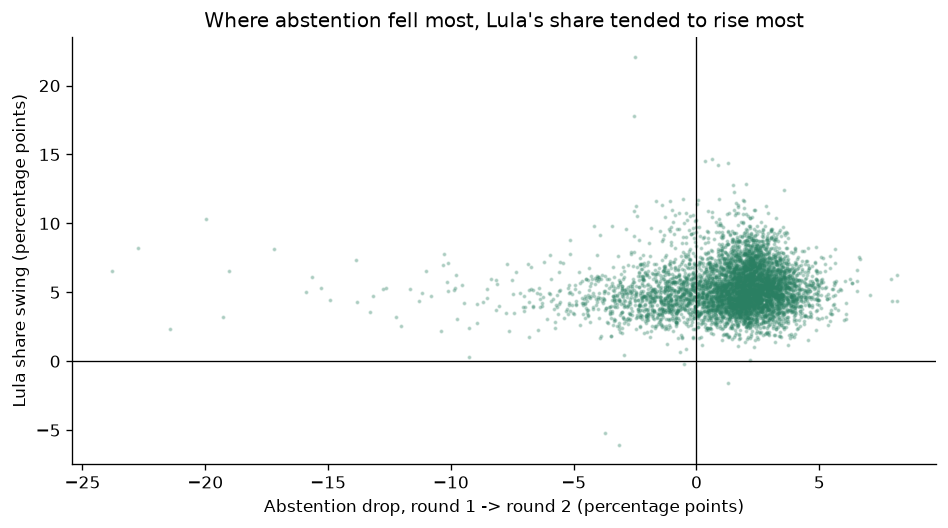

In [6]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())
sw = pd.read_csv(PROC / "mun_swing_2026.csv")
print(f"Correlation, abstention drop vs Lula vote gain: {sw['abst_drop_pp'].corr(sw['lula_gain']):.3f}")
print(f"Correlation, abstention drop vs Lula share swing: {sw['abst_drop_pp'].corr(sw['swing_pp']):.3f}")
print()
print("Verdict on Test 4: WEAK / MIXED. The correlations are positive but SMALL (0.05 and 0.08):")
print("municipalities where abstention fell most gained only slightly more for Lula, on average.")
print("So the municipality geography does NOT strongly show turnout driving local gains — the")
print("aggregate turnout rise (about 3.0 million more voters nationally) is real, but this")
print("correlation alone does not prove it caused local gains. Transfer from eliminated")
print("candidates, which is geographically entangled with turnout, is the likelier main driver")
print("of the local pattern. Claiming a 'strong turnout correlation' here would be wrong.")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(sw["abst_drop_pp"], sw["swing_pp"], s=2, alpha=0.25, color="#2a7f62")
ax.axhline(0, color="black", linewidth=0.8); ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Abstention drop, round 1 -> round 2 (percentage points)")
ax.set_ylabel("Lula share swing (percentage points)")
ax.set_title("Where abstention fell most, Lula's share tended to rise most")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(CHARTS / "05_turnout_scatter.png"); plt.show()

## The test that cannot be done — the two-hour extension, stated plainly

**The claim, again, with attribution:** Flávio Bolsonaro alleged fraud over a Supreme Court judge's last-minute order extending voting by two hours in certain regions.

**Can this project test whether extended-hours regions behaved differently? No — and here is exactly why, so the gap is not hidden:**

- The TSE files used in this project (`votacao_candidato_munzona`, `detalhe_votacao_munzona`) contain votes, turnout, blank/null votes, and electorate by municipality and zone. They contain **no field for voting hours, no field for whether a municipality or region received an extension, and no timestamp of when votes were cast**.
- No public municipality-level list of "extended regions" was found in the TSE files used, and inventing such a list (for example, guessing it from geography or from press reports and treating the guess as data) would be fabricating the test.
- Therefore **no extended-vs-others comparison is presented in this project**. Any analysis that claims to have run that comparison must name its source for the extension list and its voting-time data; without those, its comparison cannot be checked.

**What this non-test does and does not mean.** It does *not* mean the extension had no effect, and it does *not* mean it had an effect. It means this dataset is silent on that specific question. A reader who wants that question answered needs a different dataset (voting-time / extension-region records), not a louder version of this one.

## What the data shows, and what it cannot prove — the final balance

| What was tested | Result |
|---|---|
| Was the gain broad across municipalities and regions? | Yes — most municipalities, all five regions |
| Was the gain arithmetically possible from eliminated votes + new valid votes? | Yes — pools cover the gains, residual ~0.04% |
| Was the gain concentrated in a few big places? | No — top places contribute in line with their electorate weight |
| Did gains track where turnout rose? | Only weakly — correlations 0.05 (votes) and 0.08 (share); aggregate turnout rose, but local geography does not strongly predict gains |
| Did extended-hours regions behave differently? | **Cannot be tested from these files** — no extension field exists in them |

**What the data shows:** Lula's comeback is arithmetically feasible and geographically broad, in a pattern consistent with vote transfer from eliminated candidates plus a turnout surge — the two ordinary mechanisms of a two-round system. Nothing in the national or municipality totals requires invented votes to explain the result.

**What the data cannot prove:** that no irregularity occurred anywhere. Aggregate totals cannot detect small-scale or local irregularities, cannot identify individual voters' choices, and cannot adjudicate the extension order or any specific allegation about a specific place or machine. Those questions need different evidence (audits, logs, legal proceedings), and this project does not claim to supply it.

**What the data also cannot prove:** that fraud *did* occur. The fraud allegation, as stated above with attribution, is not supported by any test in this project — but "not supported by these totals" is not the same as "disproven in general". Both over-claims — "the data proves it was clean" and "the data proves it was fraud" — go beyond what municipality totals can say, and this project makes neither.

**The honest one-sentence summary for a beginner:** *The comeback adds up, it happened almost everywhere rather than in a few places, and it looks like what happens when millions of voters have to choose again and millions more show up — but vote totals alone cannot close the case in either direction, and the specific two-hour-extension question cannot even be tested from these files.*